# Crop Filtering (PPS/IMERG, SMAP) MCD12Q1 mask

In [1]:
import pandas as pd
import numpy as np
from pyhdf.SD import SD, SDC
from pathlib import Path
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

## Load the MCD12Q1 cropland mask 

In [2]:
cropland_mask = pd.read_parquet(
    '/global/scratch/users/rubypercival/MODIS24/0.1x0.1_cropland_mask_MCD12Q1',
    engine='pyarrow')
print('Total cropland cells (MCD12Q1):', cropland_mask.shape[0])
cropland_mask.head()

Total cropland cells (MCD12Q1): 10995


,grid_lat,grid_lon,is_majority_cropland
11,36.05,-102.85,True
12,36.05,-102.75,True
13,36.05,-102.65,True
14,36.05,-102.55,True
15,36.05,-102.45,True


## Crop filter PPS/IMERG

In [3]:
precip_file = '/global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/IMERG_CONUS_0.1x0.1_hourly_filtered_2024_FIXED.parquet'
precip = pd.read_parquet(precip_file, engine='pyarrow')

precip['grid_lat'] = precip['grid_lat'].astype('float64').round(2)
precip['grid_lon'] = precip['grid_lon'].astype('float64').round(2)

print('Unique precip grid cells:', precip[['grid_lat','grid_lon']].drop_duplicates().shape[0])

Unique precip grid cells: 31200


In [4]:
precip_cropland = precip.merge(
    cropland_mask[['grid_lat', 'grid_lon']],
    on=['grid_lat', 'grid_lon'],
    how='inner')

print('Precip-cropland merged cells:', precip_cropland[['grid_lat','grid_lon']].drop_duplicates().shape[0])
precip_cropland.head()

Precip-cropland merged cells: 10995


,grid_lat,grid_lon,hour,h_precip_mm,n_halfhours
0,36.05,-102.85,2024-03-01,0.0,2
1,36.05,-102.75,2024-03-01,0.0,2
2,36.05,-102.65,2024-03-01,0.0,2
3,36.05,-102.55,2024-03-01,0.0,2
4,36.05,-102.45,2024-03-01,0.0,2


### Plot: PPS/IMERG cropland-filtered cells

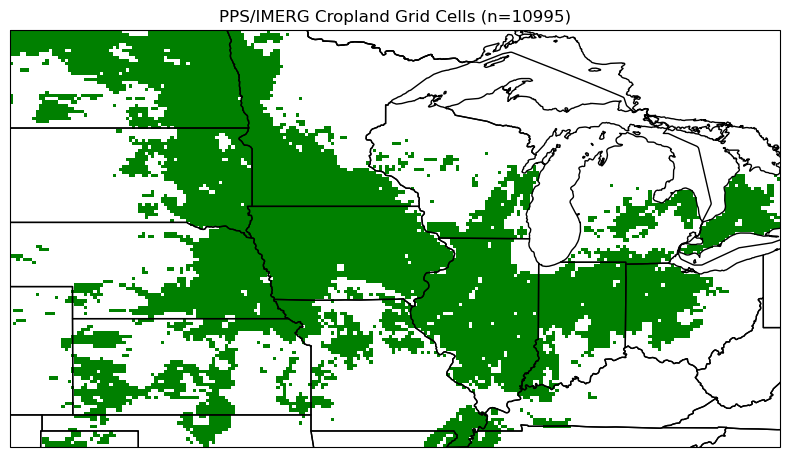

In [5]:
cropland_points = precip_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),
        0.1, 0.1,
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title(f'PPS/IMERG Cropland Grid Cells (n={len(cropland_points)})')
plt.tight_layout()
plt.savefig('/global/home/users/rubypercival/PPS_Cropland_10x10km_2024.png', dpi=300)
plt.show()


In [6]:
output = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered_MCD12Q1mask_2024.parquet'
Path(output).parent.mkdir(parents=True, exist_ok=True)
precip_cropland.to_parquet(output, engine='pyarrow')
print('Saved to:', output)


Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered_MCD12Q1mask_2024.parquet


## Crop filter SMAP

In [7]:
smap_file = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/SMAP_LAI_WFPS_0.1x0.1gridded_mar-jul24.parquet'

smap_df = pd.read_parquet(smap_file, engine='pyarrow')
smap_df = smap_df.rename(columns={'lat': 'grid_lat', 'lon': 'grid_lon'})

smap_df['grid_lat'] = smap_df['grid_lat'].astype('float64').round(2)
smap_df['grid_lon'] = smap_df['grid_lon'].astype('float64').round(2)

print('Unique SMAP grid cells:', smap_df[['grid_lat','grid_lon']].drop_duplicates().shape[0])

Unique SMAP grid cells: 31200


In [8]:
smap_cropland = smap_df.merge(
    cropland_mask[['grid_lat', 'grid_lon']],
    on=['grid_lat', 'grid_lon'],
    how='inner')

print('SMAP-cropland merged cells:', smap_cropland[['grid_lat','grid_lon']].drop_duplicates().shape[0])
smap_cropland.head()

SMAP-cropland merged cells: 10995


,datetime,grid_lat,grid_lon,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,2024-02-29 22:28:55,36.05,-102.85,0.080341,207.771500,204.572723,0.192014,0.303344,0.192158
1,2024-02-29 22:28:55,36.05,-102.75,0.103577,207.436279,204.359726,0.217320,0.303345,0.247732
2,2024-02-29 22:28:55,36.05,-102.65,0.110319,207.151962,204.182770,0.212529,0.303345,0.263858
3,2024-02-29 22:28:55,36.05,-102.55,0.116094,206.915527,204.037338,0.236859,0.304083,0.277065
4,2024-02-29 22:28:55,36.05,-102.45,0.110393,207.022614,204.150665,0.201591,0.312838,0.255790


### Plot: SMAP cropland-filtered cells

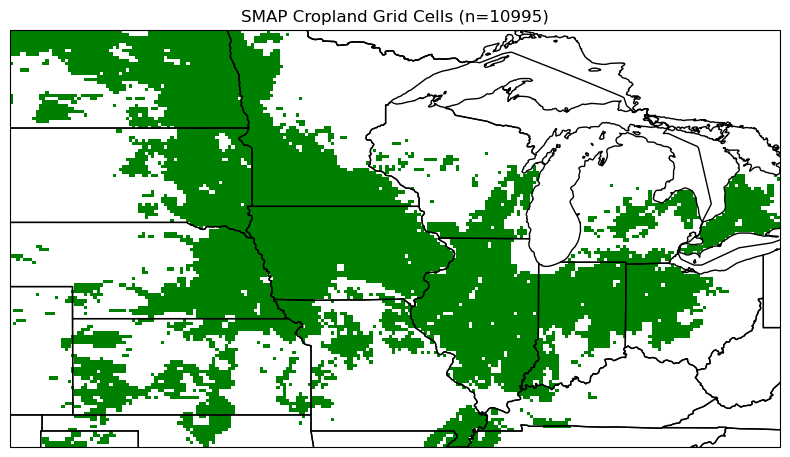

In [9]:
cropland_points = smap_cropland[['grid_lat', 'grid_lon']].drop_duplicates()

plt.figure(figsize=(8, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

for _, row in cropland_points.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),
        0.1, 0.1,
        facecolor='green',
        linewidth=0.3,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(rect)

plt.title(f'SMAP Cropland Grid Cells (n={len(cropland_points)})')
plt.tight_layout()
plt.savefig('/global/home/users/rubypercival/SMAP_Cropland_10x10km.png', dpi=300)
plt.show()


In [10]:
output = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/SMAP_03-07_0.1x0.1gridded_cropfiltered_MCD12Q1mask_2024.parquet'
Path(output).parent.mkdir(parents=True, exist_ok=True)
smap_cropland.to_parquet(output, engine='pyarrow')
print('Saved to:', output)


Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/SMAP_03-07_0.1x0.1gridded_cropfiltered_MCD12Q1mask_2024.parquet


In [11]:
tempo_file = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_V04_MCD12Q1mask_2024.parquet'
tempo_cropland = pd.read_parquet(tempo_file, engine='pyarrow')
print('TEMPO (MCD12Q1-filtered, 2024) unique cells:', tempo_cropland[['grid_lat','grid_lon']].drop_duplicates().shape[0])
print('TEMPO grid_lat dtype:', tempo_cropland['grid_lat'].dtype)

TEMPO (MCD12Q1-filtered, 2024) unique cells: 10995
TEMPO grid_lat dtype: float64
